# Gradient boosting on the validation terms (2016-2020)

`HistGradientBoostingClassifier` with the **ordinal** preprocessor from `src/preprocess.py`
(the tree-model one). Nothing in `src/` is modified here.

What this notebook does:

1. loads and splits the data exactly like the other notebooks (`load_data` -> `add_features` ->
   `add_circuit_features` -> `split_by_term` -> `handle_missing` on each X part),
2. fits **one untuned** model so we know the pipeline runs end to end,
3. tunes a small grid with `GridSearchCV` + `PredefinedSplit`, so "cross-validation" is exactly
   one fold: fit on the training terms, score on the validation terms,
4. charts the validation score of every grid setting and logs the best run to `results/yuwei.csv`.

The test terms (2021-2025) are loaded but **never touched** - they stay for task 4.2.

Run with **Restart -> Run All** on the `.venv` (Python 3.13) kernel.


In [1]:
import sys
from pathlib import Path

# make the repo root importable so `src` works from notebooks/yuwei/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline

from src.config import (
    CATEGORICAL_FEATURES,
    DERIVED_CATEGORICAL_FEATURES,
    FEATURE_COLUMNS,
    RANDOM_STATE,
)
from src.data import add_circuit_features, handle_missing, load_data
from src.evaluate import RESULTS_DIR, evaluate
from src.features import add_features
from src.preprocess import make_ordinal_preprocessor
from src.split import split_by_term

DATA_PATH = REPO_ROOT / "data" / "SCDB_2026_01_caseCentered_Citation.csv"
OWNER = "yuwei"


In [2]:
# Chart style, trimmed from ian_eda.ipynb so the charts match the rest of the project.
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID = "#fcfcfb", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 2, "figure.dpi": 110,
})


## 1. Setup: load, derive features, split by term, fill missing values

Order matters: `add_features()` needs `dateArgument`/`dateRearg`, which `handle_missing()` drops,
and `handle_missing()` also drops the target, so it runs **after** the split, on the X parts only.


In [3]:
df = load_data(DATA_PATH)
df = add_circuit_features(add_features(df))

X_train, y_train, X_val, y_val, X_test, y_test = split_by_term(df, FEATURE_COLUMNS)

# -1 for missing, 0 for threeJudgeFdc; each part is filled on its own, so nothing crosses the split
X_train = handle_missing(X_train)
X_val = handle_missing(X_val)
X_test = handle_missing(X_test)

print(f"\nfeatures: {X_train.shape[1]}  |  train {X_train.shape[0]:,} rows, val {X_val.shape[0]:,} rows")
print(f"missing values left: {int(X_train.isna().sum().sum() + X_val.isna().sum().sum())}")
X_train.head(3)


Number of rows loaded: 9,409
Number of rows after decisionType filter: 8,216
Number of rows after partyWinning filter: 8,211
train: 7,611 cases, terms 1946-2015, petitioner win rate 62.8%
  val:   305 cases, terms 2016-2020, petitioner win rate 67.2%
 test:   295 cases, terms 2021-2025, petitioner win rate 69.2%

features: 21  |  train 7,611 rows, val 305 rows
missing values left: 0


,naturalCourt,petitioner,respondent,jurisdiction,adminAction,threeJudgeFdc,caseOrigin,caseSource,lcDisagreement,certReason,...,lcDispositionDirection,issue,issueArea,term,argument_month,caseSourceCircuit,caseOriginCircuit,petitioner_is_us,respondent_is_us,was_reargued
0,1301,198.0,172.0,6.0,-1.0,0.0,51.0,29.0,0.0,11.0,...,1.0,80180.0,8.0,1946,1,9,9,0,0,1
1,1301,100.0,27.0,1.0,-1.0,0.0,123.0,30.0,0.0,4.0,...,1.0,10500.0,1.0,1946,10,10,10,0,1,1
2,1301,209.0,27.0,2.0,66.0,1.0,107.0,107.0,0.0,1.0,...,2.0,80250.0,8.0,1946,11,10,10,0,1,1


### The two numbers to beat

Both baselines in `results/baseline.csv` score **67.2% accuracy** on the validation terms, because
both of them predict "petitioner wins" for every case and the petitioner wins 67.2% of the time in
2016-2020. Predicting one class every time gives **balanced accuracy 0.5 and ROC AUC 0.5**, so any
real signal should show up there first.


In [4]:
baselines = pd.read_csv(RESULTS_DIR / "baseline.csv")
display(baselines.drop_duplicates(subset="model", keep="last")[
    ["model", "split", "n", "accuracy", "balanced_accuracy", "roc_auc"]
])

val_majority = y_val.mean()
print(f"petitioner wins {val_majority:.1%} of the {len(y_val)} validation cases "
      f"-> always-petitioner accuracy = {max(val_majority, 1 - val_majority):.1%}")


,model,split,n,accuracy,balanced_accuracy,roc_auc
2,always petitioner,val,305,0.672131,0.5,0.5
3,previous 10 terms majority,val,305,0.672131,0.5,0.5


petitioner wins 67.2% of the 305 validation cases -> always-petitioner accuracy = 67.2%


## 2. One untuned model, to check the pipeline runs

The ordinal preprocessor encodes the 17 category columns as integer codes and passes the 4 numeric
columns through. Those codes are labels, not quantities (court code 48 is not "more" than 47), so the
model is told which columns are categorical: they are the first 17 columns the `ColumnTransformer`
emits, in the order `make_ordinal_preprocessor()` lists them. Without that, boosting would split on
code numbers as if they were ordered.

Everything else is left at the sklearn defaults - that is the point of this step.


In [5]:
N_CATEGORICAL = len(CATEGORICAL_FEATURES) + len(DERIVED_CATEGORICAL_FEATURES)
CATEGORICAL_INDICES = list(range(N_CATEGORICAL))
print(f"columns treated as categorical: {N_CATEGORICAL} of {X_train.shape[1]}")


def make_pipeline(**model_params):
    """Ordinal preprocessing + HistGradientBoostingClassifier, as one unfitted Pipeline."""
    model = HistGradientBoostingClassifier(
        categorical_features=CATEGORICAL_INDICES,
        early_stopping=False,      # the validation terms are the only honest early-stopping set,
                                   # and they are already the grid's scoring fold
        random_state=RANDOM_STATE,
        **model_params,
    )
    return Pipeline([("preprocess", make_ordinal_preprocessor()), ("model", model)])


def score_on_validation(pipeline, label):
    """Fit on the training terms, score on the validation terms. Returns (y_pred, y_score)."""
    pipeline.fit(X_train, y_train)
    y_score = pipeline.predict_proba(X_val)[:, 1]
    y_pred = (y_score >= 0.5).astype(int)
    print(f"{label}:  accuracy {accuracy_score(y_val, y_pred):.3f}   "
          f"balanced accuracy {balanced_accuracy_score(y_val, y_pred):.3f}   "
          f"ROC AUC {roc_auc_score(y_val, y_score):.3f}   "
          f"predicts petitioner for {y_pred.mean():.0%} of cases")
    return y_pred, y_score


untuned = make_pipeline()
untuned_pred, untuned_score = score_on_validation(untuned, "untuned (sklearn defaults)")
UNTUNED_AUC = roc_auc_score(y_val, untuned_score)


columns treated as categorical: 17 of 21


untuned (sklearn defaults):  accuracy 0.600   balanced accuracy 0.523   ROC AUC 0.544   predicts petitioner for 73% of cases


The pipeline runs. The scores are poor: the defaults (100 trees, up to 31 leaves each, no
regularisation) fit 70 years of training terms closely and carry little of it into 2016-2020.
That is what the grid below is for.


## 3. A small grid, scored on the validation terms

`GridSearchCV` normally shuffles folds out of the training data. That is wrong here - the whole
project splits by term so that a model is judged on years it has never seen. `PredefinedSplit`
replaces the folds with a single, fixed one:

- every training row gets fold `-1`, which means "train on this, never score on it",
- every validation row gets fold `0`, the one and only scoring fold.

So each setting is fit on 1946-2015 and scored on 2016-2020, exactly like step 2.

**Scored on `roc_auc`**, for the reason in the baseline note above: accuracy on a 67/33 split mostly
rewards predicting the majority class, while ROC AUC asks whether the model ranks the cases the
petitioner actually won above the ones they lost. `refit=False` - a refit would retrain the winner on
train **and** validation, and its validation score would then mean nothing.


In [6]:
X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])

# -1 = training terms (never scored), 0 = validation terms (the single scoring fold)
test_fold = np.r_[np.full(len(X_train), -1), np.zeros(len(X_val), dtype=int)]
term_split = PredefinedSplit(test_fold)

fold_train, fold_val = next(term_split.split(X_search))
assert X_search.iloc[fold_train].index.equals(X_train.index)
assert X_search.iloc[fold_val].index.equals(X_val.index)
print(f"one fold: fit on {len(fold_train):,} training rows, score on {len(fold_val)} validation rows")

param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [4, 8, 31],
    "model__min_samples_leaf": [50, 200],
    "model__l2_regularization": [0.0, 10.0],
}
n_settings = int(np.prod([len(v) for v in param_grid.values()]))
print(f"{n_settings} settings x 1 fold = {n_settings} fits")


one fold: fit on 7,611 training rows, score on 305 validation rows
24 settings x 1 fold = 24 fits


In [7]:
search = GridSearchCV(
    make_pipeline(),
    param_grid,
    scoring="roc_auc",
    cv=term_split,
    refit=False,      # the winner is refit on the training terms only, in step 5
    n_jobs=1,
    return_train_score=True,
)
search.fit(X_search, y_search)

results = pd.DataFrame(search.cv_results_)
results = results.rename(columns={"mean_test_score": "val_roc_auc", "mean_train_score": "train_roc_auc"})
param_cols = [c for c in results.columns if c.startswith("param_model__")]
leaderboard = (results[param_cols + ["train_roc_auc", "val_roc_auc"]]
               .rename(columns=lambda c: c.replace("param_model__", ""))
               .sort_values("val_roc_auc", ascending=False)
               .reset_index(drop=True))

print(f"best validation ROC AUC {search.best_score_:.3f}   (untuned was {UNTUNED_AUC:.3f})")
print("best setting:", search.best_params_)
leaderboard


best validation ROC AUC 0.584   (untuned was 0.544)
best setting: {'model__l2_regularization': 10.0, 'model__learning_rate': 0.1, 'model__max_leaf_nodes': 8, 'model__min_samples_leaf': 200}


,l2_regularization,learning_rate,max_leaf_nodes,min_samples_leaf,train_roc_auc,val_roc_auc
0,10.0,0.10,8,200,0.871065,0.584146
1,0.0,0.05,31,200,0.918824,0.582878
2,10.0,0.10,4,200,0.785848,0.578293
3,0.0,0.10,8,200,0.873763,0.576293
4,10.0,0.05,8,50,0.815961,0.572634
5,0.0,0.10,31,200,0.973065,0.570780
6,10.0,0.05,8,200,0.816167,0.570244
7,0.0,0.05,31,50,0.939907,0.569610
8,0.0,0.10,4,200,0.785005,0.569512
9,10.0,0.05,31,200,0.901130,0.567902


Every setting scores far better on the terms it was trained on than on 2016-2020 - the gap between
the two ROC AUC columns is the overfitting the grid is trying to contain. The pattern across the
grid: **small trees and large leaves win**. Deep trees (31 leaves) with small leaves (50 cases) do
worst, which fits the problem - with 7,611 training cases spread over 70 terms and the Court's
behaviour drifting, fine-grained splits memorise old terms.


## 4. Fit chart: validation score of every grid setting


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


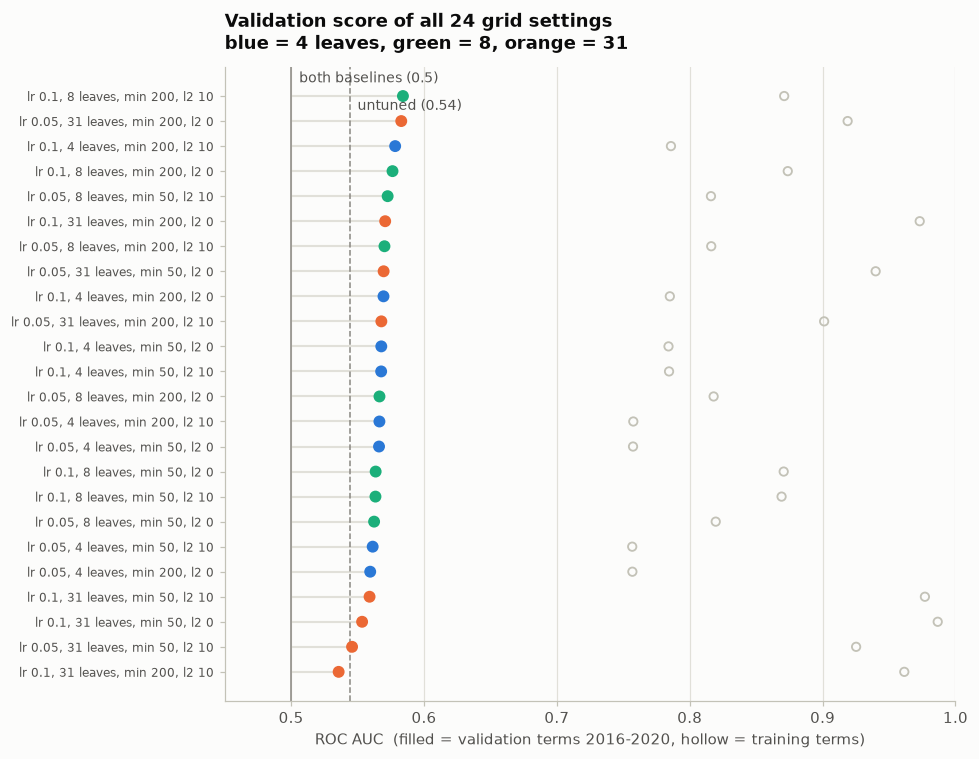

In [8]:
chart = leaderboard.sort_values("val_roc_auc").reset_index(drop=True)
labels = [f"lr {r.learning_rate}, {int(r.max_leaf_nodes)} leaves, "
          f"min {int(r.min_samples_leaf)}, l2 {r.l2_regularization:g}"
          for r in chart.itertuples()]
leaf_colors = {4: BLUE, 8: AQUA, 31: ORANGE}
colors = [leaf_colors[int(n)] for n in chart["max_leaf_nodes"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(range(len(chart)), 0.5, chart["val_roc_auc"], color=GRID, linewidth=1.4, zorder=1)
ax.scatter(chart["val_roc_auc"], range(len(chart)), s=46, color=colors, zorder=3)
ax.scatter(chart["train_roc_auc"], range(len(chart)), s=30, facecolor="none",
           edgecolor=GRAY, linewidth=1.2, zorder=2)

ax.axvline(0.5, color=MUTED, linewidth=1, zorder=1)
ax.text(0.5, len(chart) - 0.3, "  both baselines (0.5)", color=INK_2, fontsize=9, va="center")
ax.axvline(UNTUNED_AUC, color=MUTED, linewidth=1, linestyle="--", zorder=1)
ax.text(UNTUNED_AUC, len(chart) - 1.4, f"  untuned ({UNTUNED_AUC:.2f})", color=INK_2, fontsize=9, va="center")

ax.set_yticks(range(len(chart)))
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("ROC AUC  (filled = validation terms 2016-2020, hollow = training terms)")
ax.set_xlim(0.45, 1.0)
ax.grid(axis="y", visible=False)
ax.set_title(f"Validation score of all {len(chart)} grid settings\nblue = 4 leaves, green = 8, orange = 31")
plt.tight_layout()
plt.show()


## 5. The best setting, scored once and logged

The winner is refit on the **training terms only** and scored on the validation terms, so the number
logged to `results/yuwei.csv` is a genuine held-out score. `evaluate()` takes 0/1 predictions
(thresholded at 0.5) plus `predict_proba`'s petitioner column for the ROC AUC.


In [9]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
best_pipeline = make_pipeline(**best_params)
best_pred, best_score = score_on_validation(best_pipeline, "tuned best")

row = evaluate(
    "hist gradient boosting",
    best_params,
    y_val,
    best_pred,
    best_score,
    owner=OWNER,
    split="val",
)
pd.Series(row)


tuned best:  accuracy 0.626   balanced accuracy 0.535   ROC AUC 0.584   predicts petitioner for 78% of cases


timestamp                                          2026-11-18T22:49:08
owner                                                            yuwei
model                                           hist gradient boosting
params               {"l2_regularization": 10.0, "learning_rate": 0...
split                                                              val
n                                                                  305
accuracy                                                       0.62623
balanced_accuracy                                                0.535
precision                                                     0.691983
recall                                                             0.8
f1                                                            0.742081
roc_auc                                                       0.584146
tn                                                                  27
fp                                                                  73
fn    

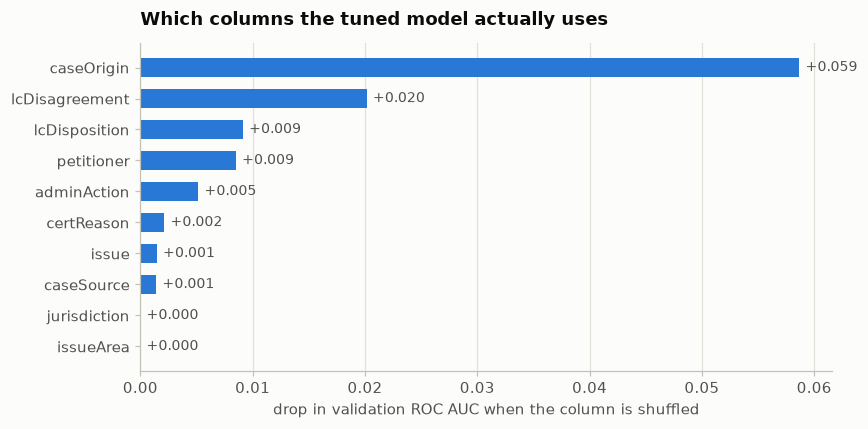

In [10]:
# What the tuned model leans on: permutation importance on the validation terms.
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_pipeline, X_val, y_val, scoring="roc_auc",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=1,
)
top = (pd.Series(importance.importances_mean, index=X_val.columns)
       .sort_values(ascending=False).head(10)[::-1])

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(top.index, top.values, height=0.6,
               color=[BLUE if v > 0 else GRAY for v in top.values])
ax.bar_label(bars, labels=[f"{v:+.3f}" for v in top.values], padding=4, color=INK_2, fontsize=9)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_xlabel("drop in validation ROC AUC when the column is shuffled")
ax.grid(axis="y", visible=False)
ax.set_title("Which columns the tuned model actually uses")
plt.tight_layout()
plt.show()


In [11]:
pd.read_csv(RESULTS_DIR / f"{OWNER}.csv")


,timestamp,owner,model,params,split,n,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,2026-11-18T22:49:08,yuwei,hist gradient boosting,"{""l2_regularization"": 10.0, ""learning_rate"": 0...",val,305,0.62623,0.535,0.691983,0.8,0.742081,0.584146,27,73,41,164


## 6. Summary

TODO (Yuwei): three sentences.

Numbers to write them from, all on the validation terms (2016-2020, 305 cases):

| run | accuracy | balanced accuracy | ROC AUC |
| --- | --- | --- | --- |
| both baselines | 0.672 | 0.500 | 0.500 |
| untuned `HistGradientBoostingClassifier` | step 2 | step 2 | step 2 |
| tuned best | step 5 | step 5 | step 5 |

Three things worth saying:

1. what tuning bought (untuned ROC AUC vs tuned ROC AUC), and which knobs mattered
   (small trees + large leaves),
2. that ROC AUC lands above 0.5 while accuracy stays **below** the 67.2% baseline - the model ranks
   cases better than chance, but at a 0.5 threshold it is worse than just saying "petitioner wins",
3. where that leaves gradient boosting for the team: the case-level SCDB columns alone carry little
   signal about recent terms, so the gain probably has to come from the history features in
   `src/history.py` (Phase 2), not from more tuning of this model.
